# Predicting Missense Variant Pathogenicity — Phase 1: Data and Initial Baseline

**CMPS 261 — Machine Learning, Fall 2026 · Section L2**
Mohamad Ali Al Kammouni · Mohamad Malek Hotait

This notebook walks through Phase 1 of the project, from the raw ClinVar file to the initial
baseline. The heavy lifting is done by the scripts in `scripts/`; this notebook explains each
decision, checks the outputs, and shows the diagnostics.

**Contents**
1. Setup and computing environment
2. Data source and snapshot
3. Cleaning and filtering
4. Data exploration
5. Features
6. Evaluation design: the two splits
7. Initial baseline: training and tuning
8. Results
9. Diagnosis: what the model learned, and calibration
10. Summary and next steps

## 1. Setup and computing environment

Run this notebook from the repository with the `clinvar` environment selected as the kernel.

`RUN_PIPELINE = True` re-runs every script from scratch (about 5 minutes once the ClinVar file
is in `data/raw/`). With `False`, the notebook reads the outputs the scripts already produced.

In [1]:
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

# Locate the repository root whether the notebook is opened from notebooks/ or the root.
ROOT = Path.cwd().resolve()
if not (ROOT / "scripts").exists():
    ROOT = ROOT.parent
REPORTS, FIGURES = ROOT / "reports", ROOT / "reports" / "figures"

RUN_PIPELINE = False

def show_md(path):
    """Display one of the markdown reports written by the scripts."""
    display(Markdown((REPORTS / path).read_text(encoding="utf-8")))

pd.set_option("display.max_columns", 30)
print("Repository root:", ROOT)

Repository root: C:\Users\malii\Desktop\Fall26\ML\Project\project\clinvar-pathogenicity


In [2]:
PIPELINE = ["env_report.py", "download_clinvar.py", "build_dataset.py",
            "build_features.py", "make_splits.py", "run_baseline.py"]

if RUN_PIPELINE:
    for script in PIPELINE:
        print(f"=== {script} ===")
        result = subprocess.run([sys.executable, str(ROOT / "scripts" / script)],
                                cwd=ROOT, capture_output=True, text=True)
        print(result.stdout[-1500:])          # last lines of each script's output
        if result.returncode != 0:
            raise RuntimeError(result.stderr)
else:
    print("Using existing outputs. Set RUN_PIPELINE = True to regenerate everything.")

Using existing outputs. Set RUN_PIPELINE = True to regenerate everything.


The hardware and software used for every result in this project, recorded by
`scripts/env_report.py`. `environment.yml` pins the main package versions on any platform;
`environment-lock.yml` pins every package exactly (Windows).

In [3]:
show_md("environment.md")

# Computing environment

| Item | Value |
|---|---|
| Report generated | 2026-11-03T23:33:03 |
| Git commit | 130571b |
| OS | Windows-10-10.0.26300-SP0 |
| CPU | AMD Ryzen AI 9 HX 370 w/ Radeon 890M |
| CPU cores (physical / logical) | 12 / 24 |
| RAM | 31.1 GB |
| GPU (name, memory, driver) | NVIDIA GeForce RTX 5070 Ti Laptop GPU, 12227 MiB, 617.42 |
| Python | 3.11.18 |
| numpy | 2.4.6 |
| pandas | 3.1.0 |
| sklearn | 1.9.1 |
| matplotlib | 3.11.2 |
| pyarrow | 26.0.0 |
| PyTorch | 2.11.0+cu128 |
| PyTorch CUDA build | 12.8 |
| CUDA available | True |
| GPU (seen by PyTorch) | NVIDIA GeForce RTX 5070 Ti Laptop GPU |
| Compute capability | 12.0 |
| GPU smoke test | passed |


## 2. Data source and snapshot

We use ClinVar's `variant_summary` file from NCBI: one table of every variant with a location
on the genome, with its gene, protein change and clinical classification.

NCBI regularly replaces this file with newer releases, so results are only reproducible if
everyone uses the same copy. `scripts/download_clinvar.py` downloaded it once, checked it against NCBI's published
checksum, and recorded the release date and MD5 fingerprint below. Run on an existing file,
it verifies the file instead of downloading again, and `build_dataset.py` refuses to filter
any other file.

In [4]:
import json
snapshot = json.loads((REPORTS / "data_snapshot.json").read_text())
display(pd.Series(snapshot, name="value").to_frame())

,value
source_url,https://ftp.ncbi.nlm.nih.gov/pub/clinvar/tab_d...
release_date_server,"Sun, 01 Nov 2026 14:17:51 GMT"
downloaded_at,2026-11-04T00:02:51
size_bytes,457862838
md5,d7e0d7e581e220100fc84ca64fe953ba
md5_vs_ncbi,match


## 3. Cleaning and filtering

`scripts/build_dataset.py` turns 9.3 million rows into the project dataset. Each step and why:

| Step | Why |
|---|---|
| 1. Keep GRCh38 rows, one per variant | The file lists most variants twice, once per genome version. Without this, most variants would be counted twice. |
| 2. Single-nucleotide variants | Missense changes come from single-letter DNA changes. |
| 3. Missense only (from the protein change in `Name`); drop start-codon changes `p.Met1...` | The project is about one amino acid replaced by another. A start-codon change stops the protein being made at all, a different mechanism. |
| 4. Label P/LP → 1, B/LB → 0; drop VUS, conflicting and other labels | Only confident classifications can serve as ground truth. Combined labels such as "Pathogenic/Likely pathogenic" are included. |
| 5. At least one review star | Removes classifications submitted without stated criteria. |
| 6. One row per protein change | Different DNA changes can give the same amino-acid change, with identical features. Keeping copies would put the same example on both sides of a random split. Copies that agree are merged into one row (1,402 removed); the one protein change whose copies disagree (pathogenic vs benign, 2 records) is dropped. |

**Leakage rule.** The star rating comes out of the classification process, so it is used **only
for filtering**, never as a feature. The same holds for the last-evaluated date (kept only for a
later failure-analysis slice), submitter counts and condition names.

In [5]:
show_md("filtering_counts.md")

# Dataset filtering counts

Source: reports/data_snapshot.json

| Step | Variants remaining |
|---|---:|
| All rows in the snapshot | 9,345,867 |
| 1. One genome version (GRCh38), one row per variant | 4,636,853 |
| 2. Single-nucleotide variants | 4,285,982 |
| 3. Missense (one amino acid replaced by another) | 2,571,841 |
|    Start-codon changes (p.Met1...) removed | 2,567,977 |
| 4. Label is Pathogenic/Likely pathogenic or Benign/Likely benign | 216,739 |
| 5. At least one review star | 200,778 |
| 6. One row per protein change (contradictory copies dropped) | 199,374 |

## Final dataset

- Pathogenic (label 1): 59,031 (29.6%)
- Benign (label 0): 140,343 (70.4%)
- Genes: 15,272 (with both classes: 3,281)


## 4. Data exploration

We load the filtered dataset and check the label mix, the class balance and how variants are
spread across genes.

In [6]:
variants = pd.read_parquet(ROOT / "data" / "processed" / "variants.parquet")
print(f"{len(variants):,} variants, {variants['gene'].nunique():,} genes")
display(variants.head())

199,374 variants, 15,272 genes


,variation_id,gene,transcript,ref_aa,protein_pos,alt_aa,label,clinical_significance,review_status,stars,last_evaluated,chromosome,position_vcf,ref_allele,alt_allele
0,6,FOXRED1,NM_017547.4,Asn,430,Ser,1,Likely pathogenic,"criteria provided, single submitter",1,"Jun 06, 2024",11,126277517,A,G
1,19,HFE,NM_000410.4,Gln,283,Pro,1,Pathogenic/Likely pathogenic,"criteria provided, multiple submitters, no con...",2,"Jun 11, 2025",6,26092916,A,C
2,23,WDR35,NM_020779.4,Ala,864,Thr,1,Likely pathogenic,"criteria provided, single submitter",1,"May 25, 2017",2,19933469,C,T
3,30,HOGA1,NM_138413.4,Gly,287,Val,1,Pathogenic,"criteria provided, multiple submitters, no con...",2,"Nov 18, 2025",10,97611535,G,T
4,31,HOGA1,NM_138413.4,Arg,97,Cys,1,Pathogenic/Likely pathogenic,"criteria provided, multiple submitters, no con...",2,"Jun 05, 2025",10,97598852,C,T


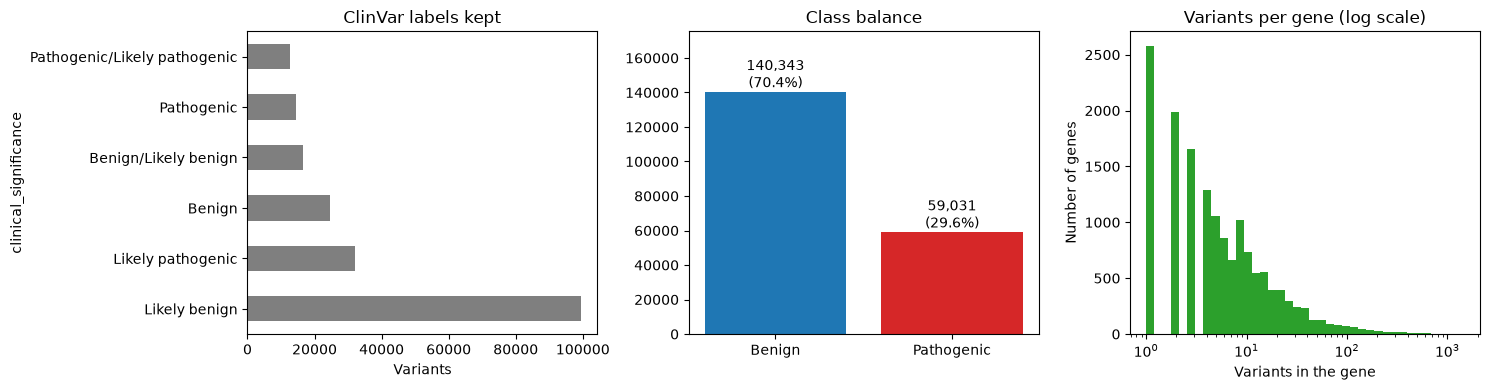

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# (a) Which ClinVar labels make up each class
variants["clinical_significance"].value_counts().plot.barh(ax=axes[0], color="tab:gray")
axes[0].set_title("ClinVar labels kept")
axes[0].set_xlabel("Variants")

# (b) Class balance
counts = variants["label"].map({0: "Benign", 1: "Pathogenic"}).value_counts()
axes[1].bar(counts.index, counts.values, color=["tab:blue", "tab:red"])
for i, v in enumerate(counts.values):
    axes[1].text(i, v, f"{v:,}\n({v / len(variants):.1%})", ha="center", va="bottom")
axes[1].set_title("Class balance")
axes[1].set_ylim(0, counts.max() * 1.25)

# (c) How many variants each gene has
per_gene = variants.groupby("gene").size()
axes[2].hist(per_gene, bins=np.logspace(0, np.log10(per_gene.max()), 40), color="tab:green")
axes[2].set_xscale("log")
axes[2].set_title("Variants per gene (log scale)")
axes[2].set_xlabel("Variants in the gene")
axes[2].set_ylabel("Number of genes")
plt.tight_layout()
plt.show()

In [8]:
# How informative is the gene by itself? Classify each gene by its mix of labels.
mix = variants.groupby("gene")["label"].agg(["mean", "size"])
kind = np.select([mix["mean"] == 0, mix["mean"] == 1], ["Only benign", "Only pathogenic"],
                 "Both classes")
summary = (pd.DataFrame({"kind": kind, "variants": mix["size"]})
           .groupby("kind").agg(genes=("variants", "size"), variants=("variants", "sum")))
summary["share of variants"] = (summary["variants"] / summary["variants"].sum()).map("{:.1%}".format)
display(summary)

top = per_gene.sort_values(ascending=False).head(10)
print("Largest genes:", ", ".join(f"{g} ({n:,})" for g, n in top.items()))
print(f"The 10 largest genes hold {top.sum() / len(variants):.1%} of all variants.")

,genes,variants,share of variants
kind,,,
Both classes,3281,127656,64.0%
Only benign,11791,70187,35.2%
Only pathogenic,200,1531,0.8%


Largest genes: FBN1 (1,464), TTN (1,242), KMT2D (1,095), SCN1A (1,053), DNAH11 (1,035), BRCA2 (835), COL4A5 (811), LDLR (705), OBSCN (691), BRCA1 (658)
The 10 largest genes hold 4.8% of all variants.


**What this shows**
- The classes are imbalanced, roughly 30% pathogenic to 70% benign. We therefore report
  **AUPRC** next to AUROC: a random guess scores the prevalence (about 0.30) on AUPRC, not 0.5.
- Most genes contain only one class. For those genes, knowing the gene gives away the answer.
  This is the shortcut the gene-grouped split is designed to expose.
- Per-gene AUROC can only be computed on genes that contain both classes.

## 5. Features

The initial baseline uses only properties of the swap itself (`scripts/build_features.py`):
which amino acid was lost and which one replaced it. Nothing about the gene, the position, the
review status or the date is used.

| Feature group | Source |
|---|---|
| BLOSUM62 score: how often evolution tolerates this swap | Henikoff & Henikoff (1992) |
| Side-chain volume: old, new, change, size of change | Zamyatnin (1972) |
| Hydrophobicity: old, new, change, size of change | Kyte & Doolittle (1982) |
| Charge: old, new, change, whether it changed | Standard charges at physiological pH |
| Cysteine, proline or glycine lost or gained | Amino acids with special structural roles |

In [9]:
show_md("feature_summary.md")

# Swap features (initial baseline)

199,374 variants, 16 features, no missing values: True

| Feature | Meaning | Mean, benign | Mean, pathogenic |
|---|---|---:|---:|
| `blosum62` | BLOSUM62 score of the swap (low = rarely tolerated in evolution) | -0.01 | -1.15 |
| `ref_volume` | Side-chain volume of the original amino acid | 131.08 | 128.60 |
| `alt_volume` | Side-chain volume of the new amino acid | 136.14 | 138.14 |
| `delta_volume` | Change in volume (new - original) | 5.05 | 9.54 |
| `abs_delta_volume` | Size of the volume change, ignoring direction | 35.92 | 50.78 |
| `ref_hydro` | Hydrophobicity of the original amino acid | -0.63 | -0.63 |
| `alt_hydro` | Hydrophobicity of the new amino acid | -0.13 | -0.77 |
| `delta_hydro` | Change in hydrophobicity (new - original) | 0.50 | -0.14 |
| `abs_delta_hydro` | Size of the hydrophobicity change, ignoring direction | 2.18 | 3.15 |
| `ref_charge` | Charge of the original amino acid | 0.10 | 0.08 |
| `alt_charge` | Charge of the new amino acid | 0.05 | 0.07 |
| `delta_charge` | Change in charge (new - original) | -0.05 | -0.01 |
| `charge_changed` | 1 if the charge changes at all | 0.33 | 0.46 |
| `involves_cys` | 1 if cysteine is lost or gained (disulfide bonds) | 0.04 | 0.14 |
| `involves_pro` | 1 if proline is lost or gained (breaks helices) | 0.10 | 0.13 |
| `involves_gly` | 1 if glycine is lost or gained (backbone flexibility) | 0.10 | 0.22 |


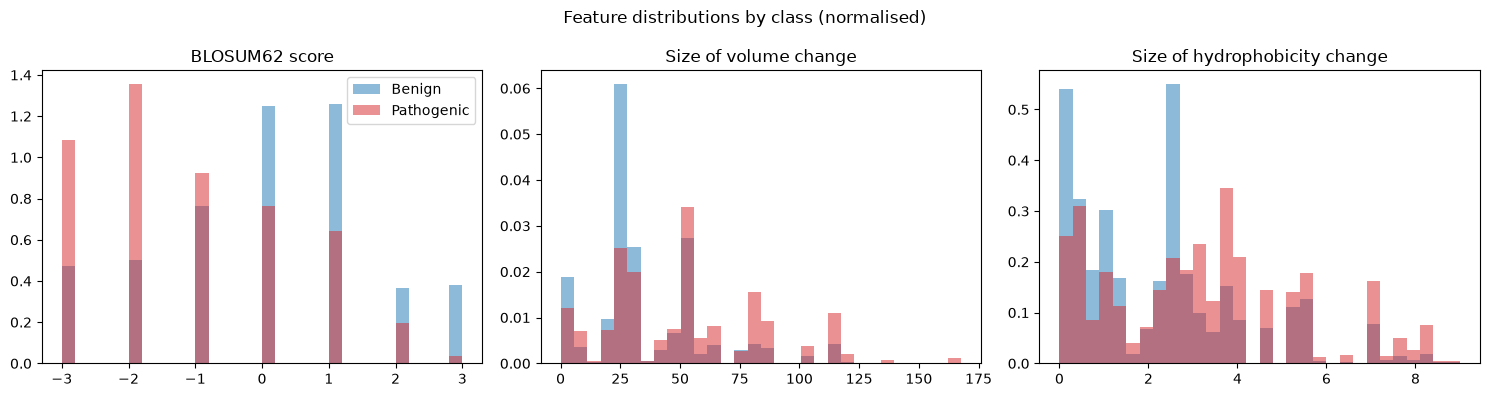

In [10]:
feats = pd.read_parquet(ROOT / "data" / "processed" / "features_swap.parquet")
FEATURES = [c for c in feats.columns if c not in ("variation_id", "gene", "label")]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col, title in zip(axes, ["blosum62", "abs_delta_volume", "abs_delta_hydro"],
                          ["BLOSUM62 score", "Size of volume change", "Size of hydrophobicity change"]):
    for lab, name, color in [(0, "Benign", "tab:blue"), (1, "Pathogenic", "tab:red")]:
        ax.hist(feats.loc[feats["label"] == lab, col], bins=30, density=True,
                alpha=0.5, label=name, color=color)
    ax.set_title(title)
axes[0].legend()
plt.suptitle("Feature distributions by class (normalised)")
plt.tight_layout()
plt.show()

Every feature moves in the direction biology predicts. Pathogenic swaps have lower BLOSUM62
scores (rarer in evolution) and larger changes in size and hydrophobicity. Cysteine and glycine
are much more often involved. The original amino acid's own properties barely differ between
classes: the signal is in the **change**.

## 6. Evaluation design: the two splits

`scripts/make_splits.py` assigns every variant to train (70%), val (10%) or test (20%) in two
ways, each repeated with 5 seeds:

- **Random split:** variants are shuffled. A val/test variant's gene is usually also in training.
- **Gene split:** whole genes go to one side, so no val/test gene is ever seen in training.

Both keep the pathogenic share equal across the three parts.

| Part | Use |
|---|---|
| train | Fitting, and hyperparameter tuning by cross-validation inside train only |
| val | Preliminary results (progress report) and later recalibration |
| test | Untouched until the final results |

In [11]:
splits = pd.read_parquet(ROOT / "data" / "splits" / "splits.parquet")
if not (splits["variation_id"].values == feats["variation_id"].values).all():
    raise RuntimeError("Features and splits are not in the same order.")

# Independent check of the key property: share of val genes that also appear in train.
genes = feats["gene"].values
rows = []
for col in [c for c in splits.columns if c != "variation_id"]:
    part = splits[col].values
    train_genes = set(genes[part == "train"])
    val_genes = set(genes[part == "val"])
    rows.append({"split": col,
                 "val variants": int((part == "val").sum()),
                 "val genes": len(val_genes),
                 "val genes also in train": f"{len(val_genes & train_genes) / len(val_genes):.1%}"})
display(pd.DataFrame(rows).set_index("split"))

,val variants,val genes,val genes also in train
split,,,
random_s0,19938,6811,94.4%
gene_s0,19915,1513,0.0%
random_s1,19938,6850,93.8%
gene_s1,19917,1520,0.0%
random_s2,19938,6808,94.1%
gene_s2,19926,1542,0.0%
random_s3,19938,6777,94.4%
gene_s3,19929,1545,0.0%
random_s4,19938,6815,94.3%


In the random split more than 90% of val genes were seen in training; in the gene split, none
were. Any difference in results between the two can therefore only come from facing unseen genes.

## 7. Initial baseline: training and tuning

**Model.** Standardised features, then L2-regularised logistic regression. It is fast, and its
coefficients can be read directly, which makes it the interpretable reference of the model ladder.

**Tuning.** The regularisation strength `C` is chosen by 5-fold **gene-grouped** cross-validation
inside the training part, scored by AUPRC. The validation part plays no role in tuning.

**No class weighting.** AUROC and AUPRC depend only on how variants are ranked, which weighting
barely changes, while weighting distorts the predicted probabilities that the calibration
analysis relies on.

**Gene-only reference (diagnostic, not a model).** Predicts each variant by the share of
pathogenic variants its gene had in training, using nothing about the swap. Its score measures
how much "knowing the gene" alone is worth.

Below we repeat the tuning for one run (gene split, seed 0) to show the tuning curve.

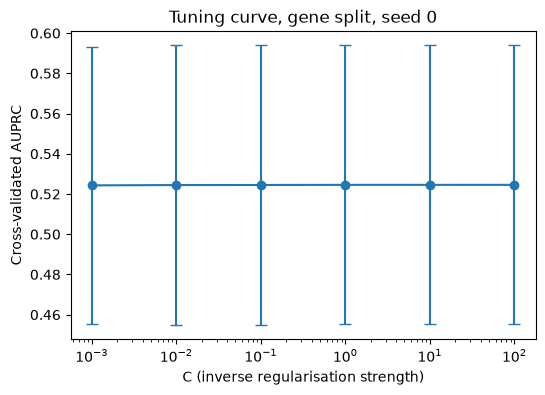

Best C: 100
CV AUPRC range across the grid: 0.5243 – 0.5246


In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
C_GRID = [0.001, 0.01, 0.1, 1, 10, 100]   # same grid as scripts/run_baseline.py

train = (splits["gene_s0"] == "train").values
X_tr, y_tr, g_tr = feats.loc[train, FEATURES], feats.loc[train, "label"], genes[train]

search = GridSearchCV(make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
                      {"logisticregression__C": C_GRID}, scoring="average_precision",
                      cv=GroupKFold(n_splits=5), n_jobs=-1)
search.fit(X_tr, y_tr, groups=g_tr)

cv = pd.DataFrame(search.cv_results_)
plt.figure(figsize=(6, 4))
plt.errorbar(cv["param_logisticregression__C"].astype(float), cv["mean_test_score"],
             yerr=cv["std_test_score"], marker="o", capsize=4)
plt.xscale("log")
plt.xlabel("C (inverse regularisation strength)")
plt.ylabel("Cross-validated AUPRC")
plt.title("Tuning curve, gene split, seed 0")
plt.show()
print("Best C:", search.best_params_["logisticregression__C"])
print("CV AUPRC range across the grid:",
      f"{cv['mean_test_score'].min():.4f} – {cv['mean_test_score'].max():.4f}")

The tuning curve is essentially flat: with 16 features and about 140,000 training variants the
model is far from overfitting, so regularisation hardly matters. This is why the chosen `C`
differs between seeds without any change in performance.

## 8. Results

All numbers are on the validation part, as mean ± standard deviation over 5 seeds.

In [13]:
show_md("baseline_summary.md")

# Initial baseline results (validation part, 5 seeds)

Validation prevalence (= AUPRC of a random guess): 0.296

| Model | Split | AUROC | AUPRC | Brier (lower = better) | Per-gene AUROC |
|---|---|---|---|---|---|
| gene_prior | gene | 0.500 ± 0.000 | 0.296 ± 0.000 | 0.208 ± 0.000 | 0.500 ± 0.000 |
| gene_prior | random | 0.931 ± 0.002 | 0.862 ± 0.004 | 0.091 ± 0.001 | 0.500 ± 0.000 |
| logreg | gene | 0.732 ± 0.005 | 0.530 ± 0.008 | 0.178 ± 0.001 | 0.724 ± 0.004 |
| logreg | random | 0.731 ± 0.005 | 0.529 ± 0.005 | 0.178 ± 0.001 | 0.714 ± 0.005 |

## Logistic regression: settings and cost

- Chosen C per run: [0.001, 0.01, 0.1, 10.0, 100.0]
- Training time incl. tuning (CPU): 2.3 s on average
- Inference: 0.288 ms per 1,000 variants
- Model size: 1.6 KB
- Per-gene AUROC uses val genes that contain both classes (on average 616 genes).


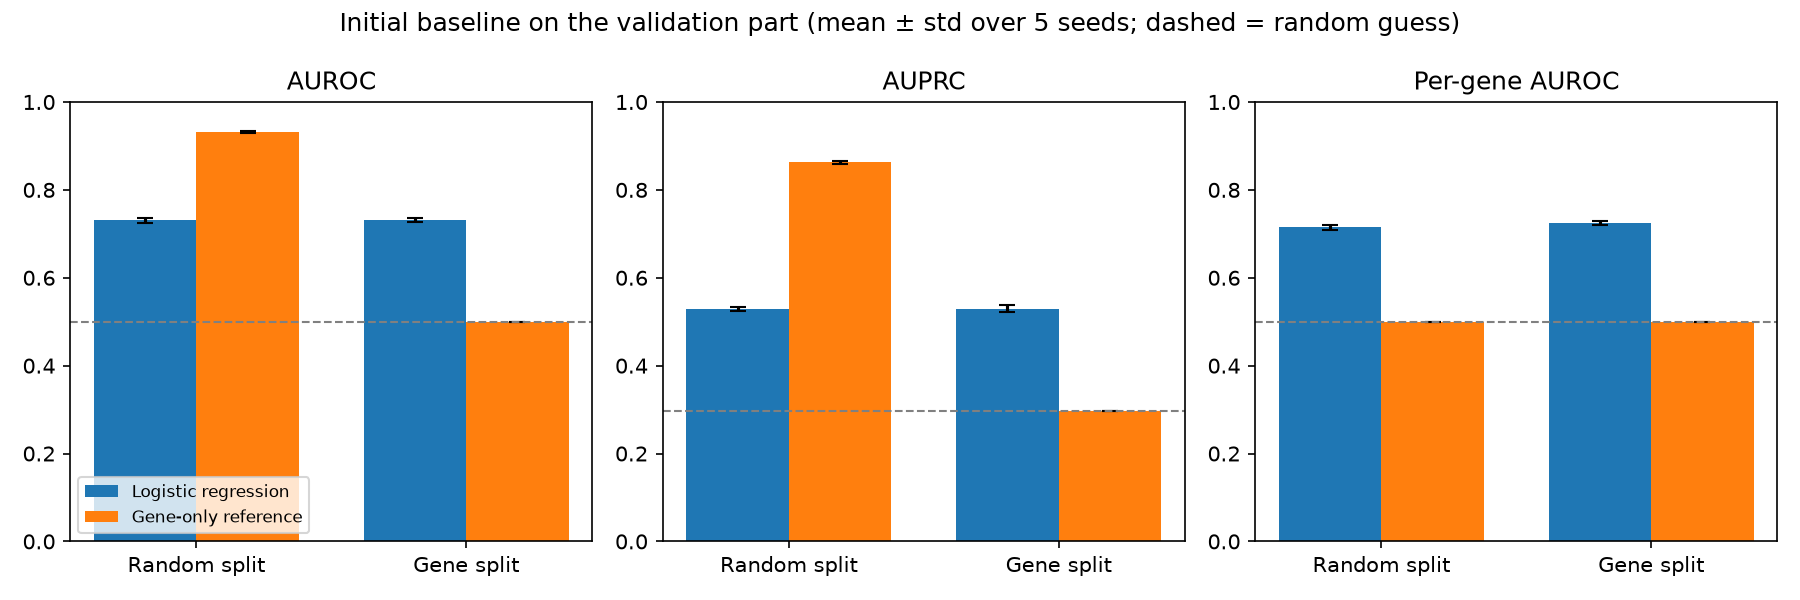

In [14]:
display(Image(str(FIGURES / "baseline_metrics.png")))

**Findings**
1. **The swap features carry real signal.** Logistic regression reaches an AUROC of about 0.73
   and an AUPRC of about 0.53, against 0.30 for a random guess.
2. **The baseline does just as well on unseen genes.** Its features contain nothing that
   identifies the gene, so it cannot use the gene shortcut. What it learned transfers.
3. **Knowing only the gene beats the biology on the random split** (AUROC about 0.93), then
   falls to chance on unseen genes. A random split therefore rewards recognising genes. Any
   later feature that can identify the gene (protein length, position, protein language model
   embeddings) must be judged on the gene split.
4. **Per-gene AUROC** is about 0.72 for the model and 0.50 for the gene-only reference: the
   model ranks variants within a gene, which the gene-only reference cannot.
5. **Results are stable**: the spread across seeds is about ±0.005.

## 9. Diagnosis: what the model learned, and calibration

**Coefficients.** Features are standardised, so coefficient sizes are comparable. Positive values
push towards pathogenic. Several features are strongly correlated (the old value, the new value and
their difference are linked), so individual coefficients should be read with care; the overall
direction of each feature group is what matters.

In [15]:
show_md("baseline_coefficients.md")

# Logistic regression coefficients (gene split, seed 0)

Features are standardised, so sizes are comparable. Positive = pushes towards pathogenic.

| Feature | Coefficient |
|---|---:|
| `blosum62` | -0.653 |
| `ref_charge` | -0.177 |
| `delta_hydro` | -0.173 |
| `alt_hydro` | -0.167 |
| `alt_charge` | -0.139 |
| `delta_volume` | -0.026 |
| `abs_delta_volume` | -0.003 |
| `ref_hydro` | +0.010 |
| `involves_pro` | +0.014 |
| `abs_delta_hydro` | +0.015 |
| `charge_changed` | +0.037 |
| `delta_charge` | +0.044 |
| `alt_volume` | +0.208 |
| `ref_volume` | +0.226 |
| `involves_cys` | +0.239 |
| `involves_gly` | +0.337 |


**Calibration.** If the model says 70% pathogenic, about 70% of such variants should be
pathogenic. Points on the diagonal mean the probabilities can be taken at face value.

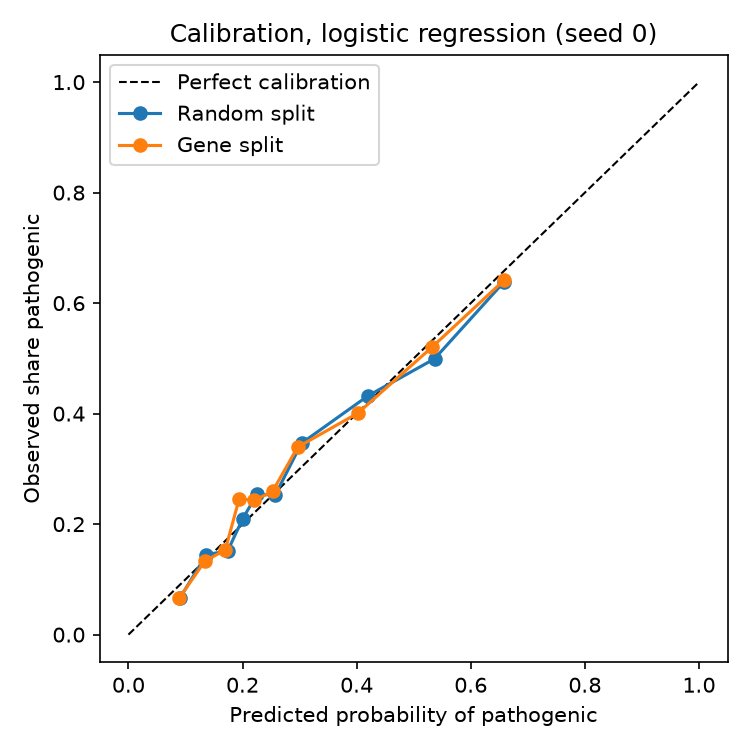

In [16]:
display(Image(str(FIGURES / "baseline_calibration.png")))

In [17]:
# Expected calibration error (ECE): average gap between predicted and observed rates,
# weighted by how many variants fall in each bin. 0 = perfectly calibrated.
import joblib

def expected_calibration_error(y, p, n_bins=10):
    bins = np.quantile(p, np.linspace(0, 1, n_bins + 1))
    idx = np.clip(np.digitize(p, bins[1:-1]), 0, n_bins - 1)
    return sum((idx == b).mean() * abs(y[idx == b].mean() - p[idx == b].mean())
               for b in range(n_bins) if (idx == b).any())

for split_type in ["random", "gene"]:
    model = joblib.load(ROOT / "models" / f"baseline_lr_{split_type}_s0.joblib")
    val = (splits[f"{split_type}_s0"] == "val").values
    p = model.predict_proba(feats.loc[val, FEATURES].to_numpy())[:, 1]
    y = feats.loc[val, "label"].values
    print(f"{split_type:>6} split: ECE = {expected_calibration_error(y, p):.3f}, "
          f"predicted probabilities range {p.min():.2f} – {p.max():.2f}")

random split: ECE = 0.018, predicted probabilities range 0.07 – 0.78
  gene split: ECE = 0.018, predicted probabilities range 0.07 – 0.80


A low ECE means the probabilities are trustworthy on average. Note the range of predicted
probabilities: swap features alone rarely let the model be very confident either way, which
limits how useful the scores are for prioritisation. Calibration will be revisited for every
model, separately on familiar and unseen genes (proposal, sub-question 3).

## 10. Summary and next steps

**Done in Phase 1**
- Reproducible pipeline: pinned environment, verified data snapshot, scripted steps.
- 199,374 missense variants in 15,272 genes, with a documented leakage audit.
- Random and gene-grouped splits, 5 seeds each, with the test part kept untouched.
- Initial baseline: logistic regression on swap features, about 0.73 AUROC under both splits.
- Diagnostic showing that gene identity alone gives 0.93 AUROC on a random split and 0.50 on
  unseen genes.

**Next (towards the final submission)**
1. Add protein length and relative position (UniProt) and conservation (phyloP).
2. Gradient-boosted trees as the strong Level-1 baseline.
3. Level 2: ESM-2 embeddings of the wild-type and mutant protein, plus a zero-shot ESM-2 score.
4. Allele frequency (gnomAD) as a separate ablation only.
5. Calibration and recalibration on separate validation genes; abstention option.
6. Failure analysis on the slices defined in the proposal.
7. Complexity analysis: time, hardware, model size and interpretability for every model.
8. Final evaluation on the untouched test part.